# 02 - Batch integration with scVI
Integrate the 22 libraries into one shared latent space so that cell types, rather than patients or sequencing runs, drive the structure of the embedding.

**Design choices**
- Batch key is the **library** (`sample`): technical effects are per library, and one patient contributes several libraries.
- Response is **not** given to the model. Each patient is wholly responder or non-responder, so regressing out patient would erase the signal; response is tested afterwards on cell-type composition and pseudobulk expression.
- 3,000 highly variable genes (Seurat v3, selected within each library and then combined).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scanpy as sc, scvi, matplotlib.pyplot as plt
sc.settings.set_figure_params(dpi=100, frameon=False)
scvi.settings.seed = 0
FIG = "../results/figures/"
adata = sc.read_h5ad("../data/processed/cd45_qc.h5ad")
adata

Seed set to 0


AnnData object with n_obs × n_vars = 87486 × 23266
    obs: 'gsm', 'patient', 'sample', 'timepoint', 'biopsy_site', 'best_overall_response', 'response', 'tls', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'outlier', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'sample_colors', 'scrublet'
    layers: 'counts', None (.X)

## 1. Normalise (for display and later marker analysis) and select HVGs

In [2]:
adata.X = adata.layers["counts"].copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata                      # full gene set, log-normalised
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=3000, batch_key="sample", layer="counts", subset=True)
adata

AnnData object with n_obs × n_vars = 87486 × 3000
    obs: 'gsm', 'patient', 'sample', 'timepoint', 'biopsy_site', 'best_overall_response', 'response', 'tls', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'outlier', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'sample_colors', 'scrublet', 'log1p', 'hvg'
    layers: 'counts', None (.X)

## 2. Baseline: unintegrated PCA embedding

In [3]:
def knn_batch_entropy(a, key="sample"):
    """Mean normalised entropy of the library labels among each cell's kNN (1 = perfectly mixed)."""
    d = a.obsp["distances"].tocsr()
    k = np.diff(d.indptr); assert (k == k[0]).all()
    codes = a.obs[key].cat.codes.values
    nb = codes[d.indices.reshape(-1, k[0])]
    n = a.obs[key].nunique(); ent = np.zeros(len(nb))
    for c in range(n):
        p = (nb == c).mean(1); ent -= np.where(p > 0, p * np.log(np.where(p > 0, p, 1)), 0)
    return float((ent / np.log(n)).mean())

base = adata.copy()
sc.pp.scale(base, max_value=10)
sc.tl.pca(base, n_comps=30)
sc.pp.neighbors(base, use_rep="X_pca", n_neighbors=15)
sc.tl.umap(base)
adata.obsm["X_umap_unintegrated"] = base.obsm["X_umap"]
ent_pca = knn_batch_entropy(base); print(f"kNN library entropy, unintegrated PCA: {ent_pca:.3f}")

kNN library entropy, unintegrated PCA: 0.298


## 3. Train scVI

In [4]:
scvi.model.SCVI.setup_anndata(adata, layer="counts", batch_key="sample")
model = scvi.model.SCVI(adata, n_layers=2, n_latent=30, gene_likelihood="nb")
model.train(max_epochs=200, accelerator="cpu", batch_size=256, early_stopping=True, enable_progress_bar=False)
model.save("../data/processed/scvi_model", overwrite=True, save_anndata=False)
print("epochs trained:", len(model.history["elbo_train"]))

GPU available: True (mps), used: False


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


`Trainer.fit` stopped: `max_epochs=200` reached.


epochs trained: 200


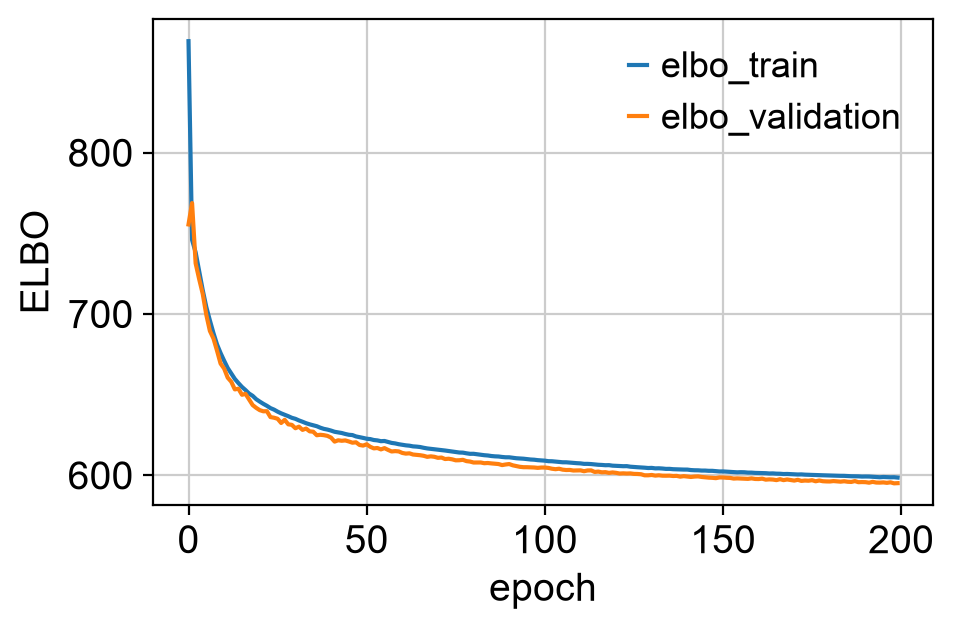

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.2))
model.history["elbo_train"].plot(ax=ax); model.history["elbo_validation"].plot(ax=ax)
ax.set_xlabel("epoch"); ax.set_ylabel("ELBO"); ax.legend(frameon=False)
plt.savefig(FIG + "02_scvi_training_curve.png", dpi=150, bbox_inches="tight")

## 4. Latent space, UMAP and clustering

In [6]:
adata.obsm["X_scVI"] = model.get_latent_representation()
sc.pp.neighbors(adata, use_rep="X_scVI", n_neighbors=15)
sc.tl.umap(adata)
sc.tl.leiden(adata, resolution=0.8, flavor="igraph", n_iterations=2, directed=False, key_added="leiden")
ent_scvi = knn_batch_entropy(adata)
print(f"kNN library entropy: unintegrated PCA {ent_pca:.3f} -> scVI {ent_scvi:.3f}")
print("clusters:", adata.obs["leiden"].nunique())

kNN library entropy: unintegrated PCA 0.298 -> scVI 0.394
clusters: 22


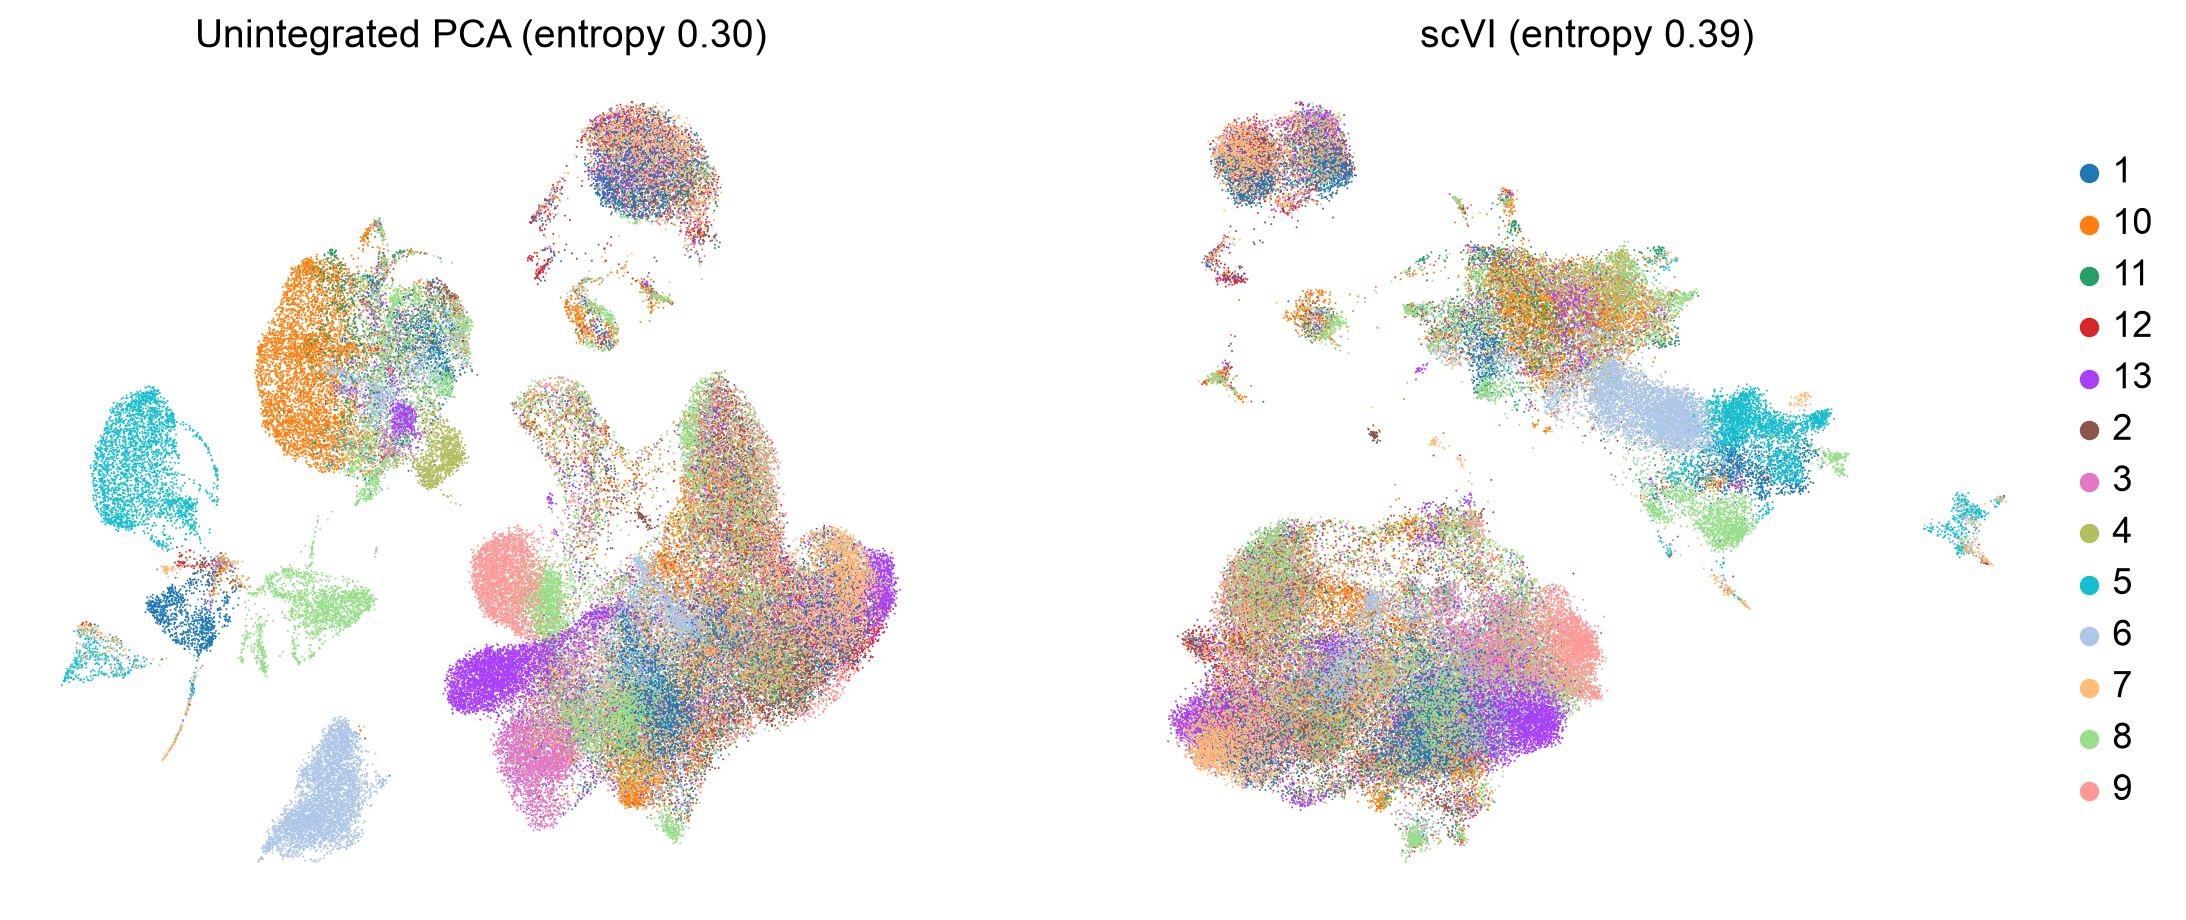

In [7]:
adata.obsm["X_umap_scvi"] = adata.obsm["X_umap"].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, key, title in zip(axes, ["X_umap_unintegrated", "X_umap_scvi"], [f"Unintegrated PCA (entropy {ent_pca:.2f})", f"scVI (entropy {ent_scvi:.2f})"]):
    adata.obsm["X_umap"] = adata.obsm[key]
    sc.pl.umap(adata, color="patient", ax=ax, show=False, title=title, legend_loc="right margin" if key.endswith("scvi") else None, size=2)
adata.obsm["X_umap"] = adata.obsm["X_umap_scvi"]
plt.savefig(FIG + "02_umap_unintegrated_vs_scvi.png", dpi=150, bbox_inches="tight")

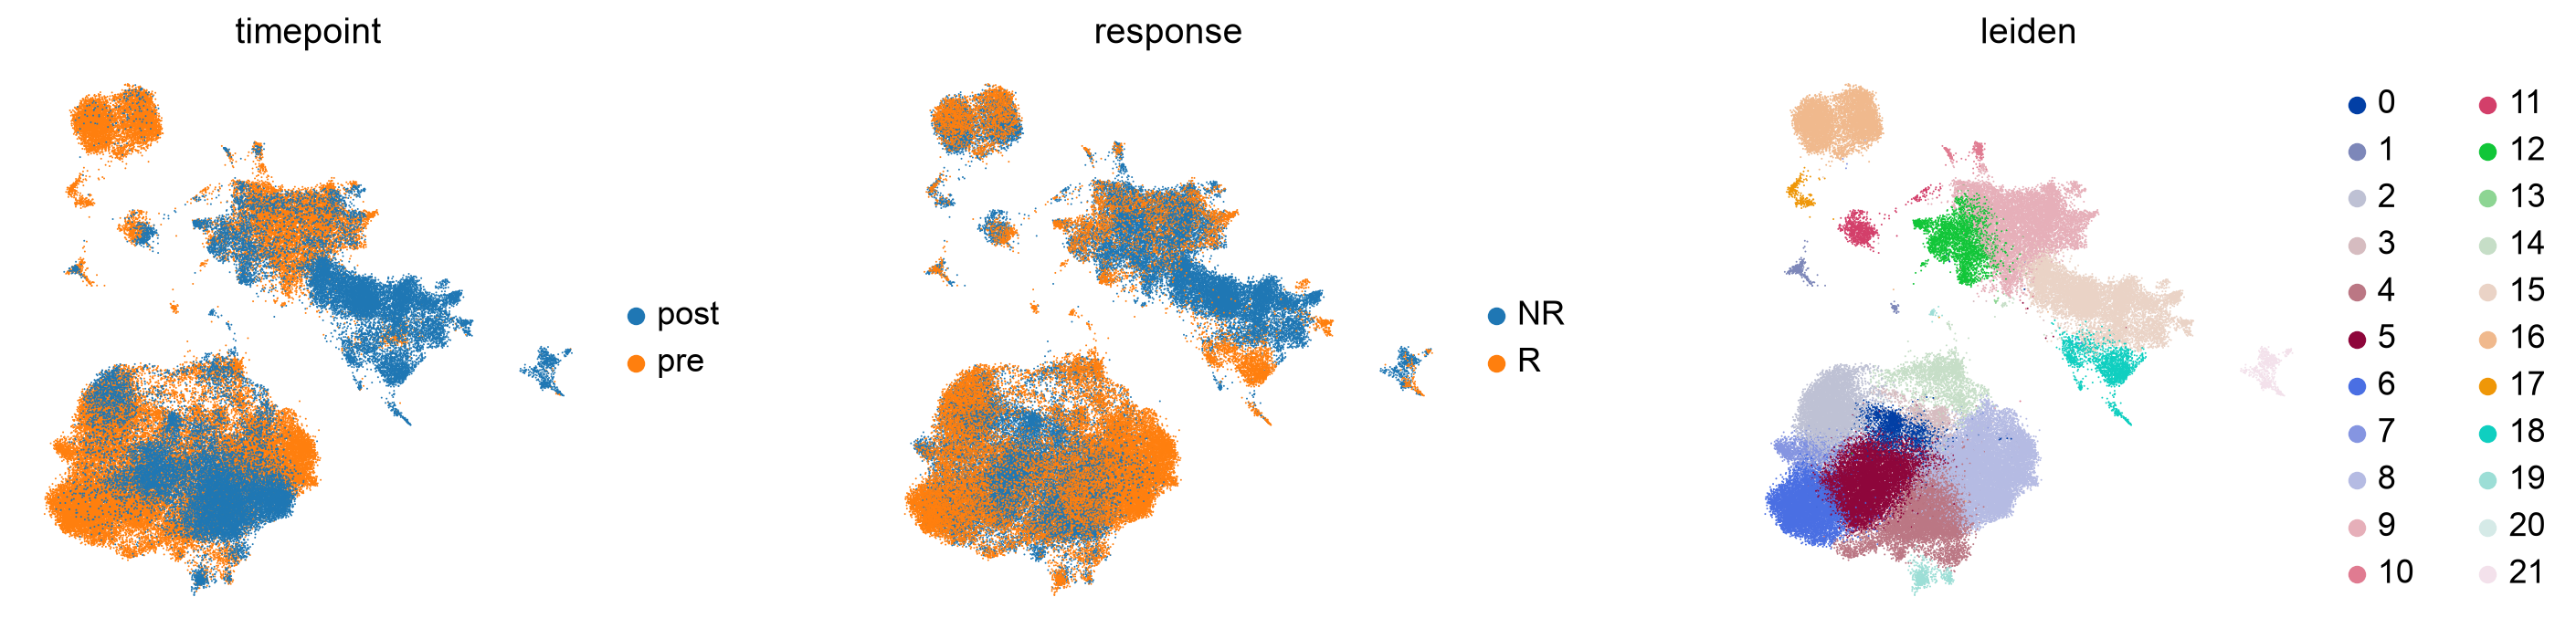

In [8]:
sc.pl.umap(adata, color=["timepoint", "response", "leiden"], ncols=3, size=2, wspace=0.35, show=False)
plt.savefig(FIG + "02_umap_scvi_metadata.png", dpi=150, bbox_inches="tight")

## 5. Are any clusters driven by a single patient?

In [9]:
ct = pd.crosstab(adata.obs["leiden"], adata.obs["patient"])
frac = ct.div(ct.sum(1), axis=0)
diag = pd.DataFrame({"cells": ct.sum(1), "top_patient": frac.idxmax(1), "top_patient_frac": frac.max(1).round(2),
                     "patients_with_>=1%": (frac >= 0.01).sum(1)})
diag.sort_values("top_patient_frac", ascending=False).head(10)

,cells,top_patient,top_patient_frac,patients_with_>=1%
leiden,,,,
13,11,10,1.00,1
18,1768,8,0.79,6
21,553,5,0.64,6
17,303,12,0.50,5
15,9056,6,0.49,5
9,9762,10,0.48,9
0,2075,10,0.46,7
19,549,8,0.45,12
11,814,10,0.41,11


In [10]:
adata.write_h5ad("../data/processed/cd45_integrated.h5ad", compression="gzip")
adata

AnnData object with n_obs × n_vars = 87486 × 3000
    obs: 'gsm', 'patient', 'sample', 'timepoint', 'biopsy_site', 'best_overall_response', 'response', 'tls', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'outlier', 'n_genes', 'doublet_score', 'predicted_doublet', '_scvi_batch', '_scvi_labels', 'leiden'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'sample_colors', 'scrublet', 'log1p', 'hvg', '_scvi_uuid', '_scvi_manager_uuid', 'neighbors', 'umap', 'leiden', 'patient_colors', 'timepoint_colors', 'response_colors', 'leiden_colors'
    obsm: 'X_umap_unintegrated', 'X_scVI', 'X_umap', 'X_umap_scvi'
    obsp: 'distances', 'connectivities'
    layers: 'counts', None (.X)